In [ ]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Mount your Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
paths = []
labels = []
for dirname, _, filenames in os.walk('drive/My Drive/TESS Toronto emotional speech set data'):
  for filename in filenames:
    paths.append(os.path.join(dirname, filename))
    print(filename)
    label = filename.split('_')[-1]
    print(label)
    label = label.split('.')[0]
    print(label)
    labels.append(label.lower())
print("Dataset is loaded!")


Streaming output truncated to the last 5000 lines.
happy
OAF_pike_happy.wav
happy.wav
happy
OAF_turn_happy.wav
happy.wav
happy
OAF_late_happy.wav
happy.wav
happy
OAF_red_happy.wav
happy.wav
happy
OAF_jail_happy.wav
happy.wav
happy
OAF_tip_happy.wav
happy.wav
happy
OAF_read_happy.wav
happy.wav
happy
OAF_gin_happy.wav
happy.wav
happy
OAF_wash_happy.wav
happy.wav
happy
OAF_hole_happy.wav
happy.wav
happy
OAF_lid_happy.wav
happy.wav
happy
OAF_which_happy.wav
happy.wav
happy
OAF_live_happy.wav
happy.wav
happy
OAF_mop_happy.wav
happy.wav
happy
OAF_join_happy.wav
happy.wav
happy
OAF_knock_happy.wav
happy.wav
happy
OAF_have_happy.wav
happy.wav
happy
OAF_ring_happy.wav
happy.wav
happy
OAF_thumb_happy.wav
happy.wav
happy
OAF_luck_happy.wav
happy.wav
happy
OAF_goal_happy.wav
happy.wav
happy
OAF_numb_happy.wav
happy.wav
happy
OAF_lean_happy.wav
happy.wav
happy
OAF_mode_happy.wav
happy.wav
happy
OAF_hire_happy.wav
happy.wav
happy
OAF_vote_happy.wav
happy.wav
happy
OAF_rat_happy.wav
happy.wav
happy
O

In [ ]:
len(paths)

5600

In [ ]:
labels[:5]

['disgust', 'disgust', 'disgust', 'disgust', 'disgust']

In [ ]:
paths[:5]

['drive/My Drive/TESS Toronto emotional speech set data/YAF_disgust/YAF_gaze_disgust.wav',
 'drive/My Drive/TESS Toronto emotional speech set data/YAF_disgust/YAF_cause_disgust.wav',
 'drive/My Drive/TESS Toronto emotional speech set data/YAF_disgust/YAF_bone_disgust.wav',
 'drive/My Drive/TESS Toronto emotional speech set data/YAF_disgust/YAF_bath_disgust.wav',
 'drive/My Drive/TESS Toronto emotional speech set data/YAF_disgust/YAF_check_disgust.wav']

In [ ]:
## Create a dataframe
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels
df.head()

,speech,label
0,drive/My Drive/TESS Toronto emotional speech s...,disgust
1,drive/My Drive/TESS Toronto emotional speech s...,disgust
2,drive/My Drive/TESS Toronto emotional speech s...,disgust
3,drive/My Drive/TESS Toronto emotional speech s...,disgust
4,drive/My Drive/TESS Toronto emotional speech s...,disgust


In [ ]:
df['label'].value_counts()

disgust    800
happy      800
fear       800
ps         800
angry      800
neutral    800
sad        800
Name: label, dtype: int64

In [ ]:
def waveplot(data, sr, emotion):
    plt.figure(figsize=(10,4))
    plt.title(emotion, size=20)
    librosa.display.waveshow(data, sr=sr)
    plt.show()

def spectogram(data, sr, emotion):
    x = librosa.stft(data)
    xdb = librosa.amplitude_to_db(abs(x))
    plt.figure(figsize=(11,4))
    plt.title(emotion, size=20)
    librosa.display.specshow(xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()


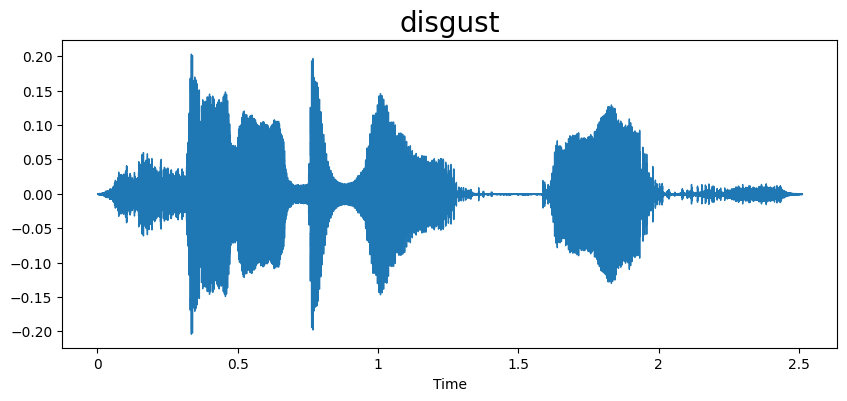

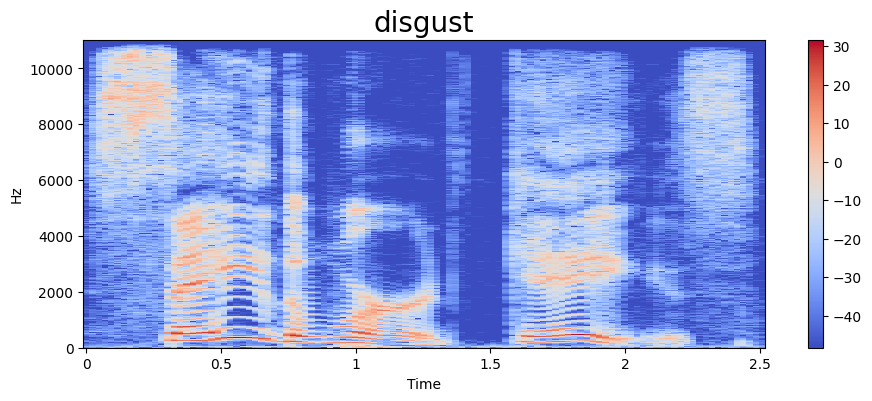

In [ ]:
emotion = 'disgust'
path = df['speech'][df['label']==emotion][0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

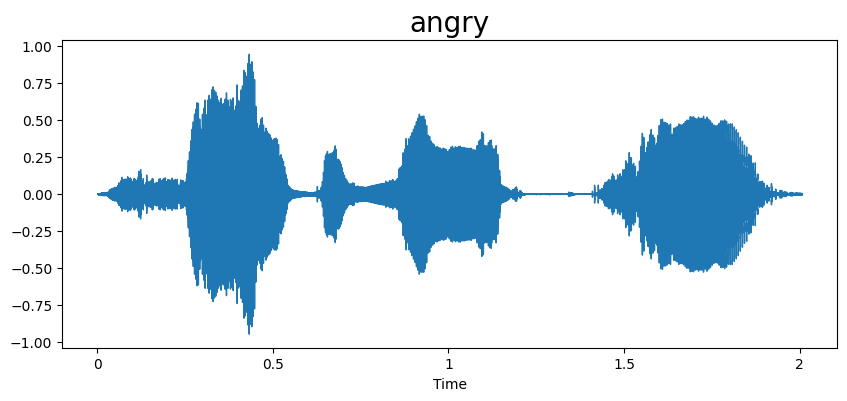

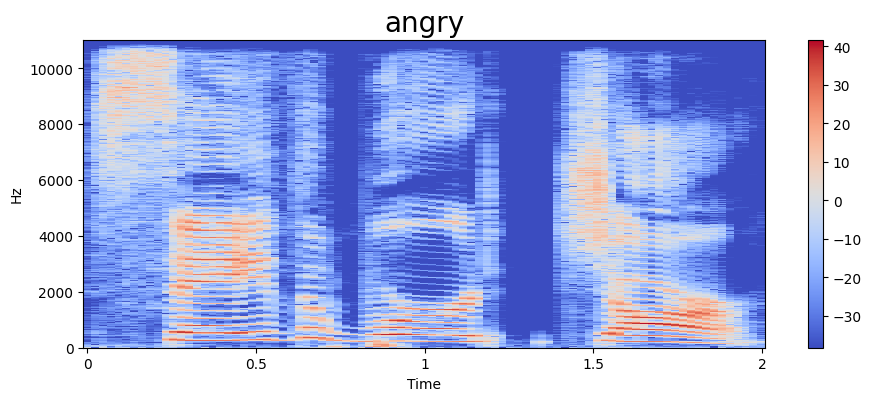

In [ ]:
emotion = 'angry'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

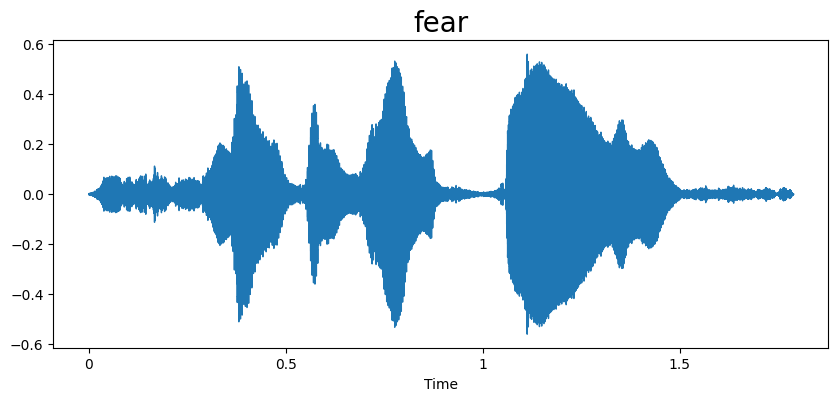

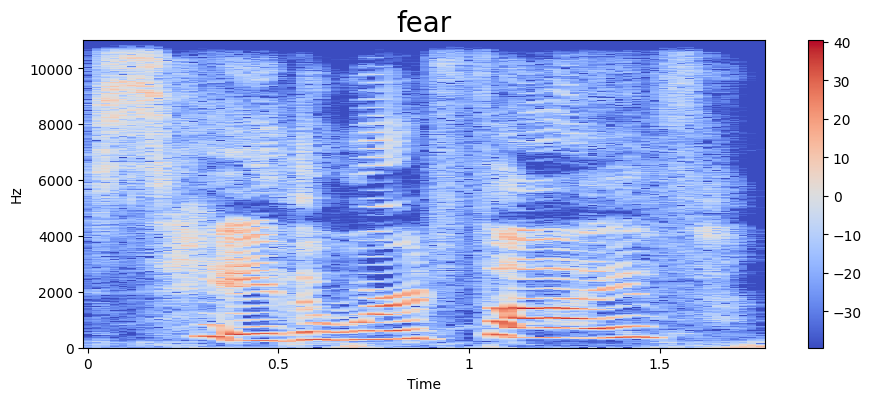

In [ ]:
emotion = 'fear'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

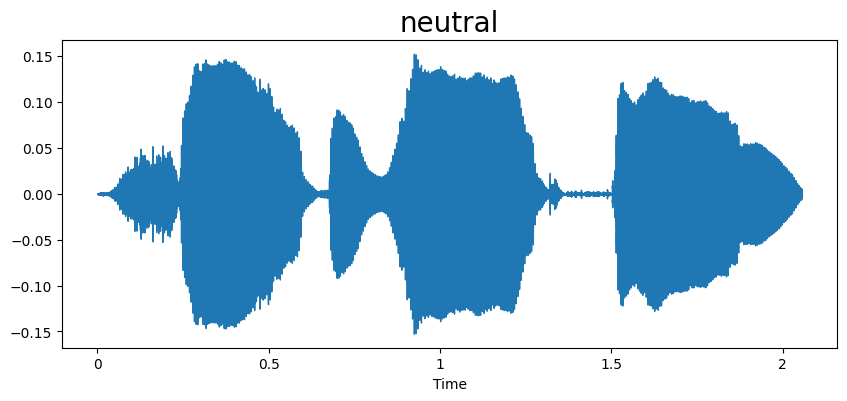

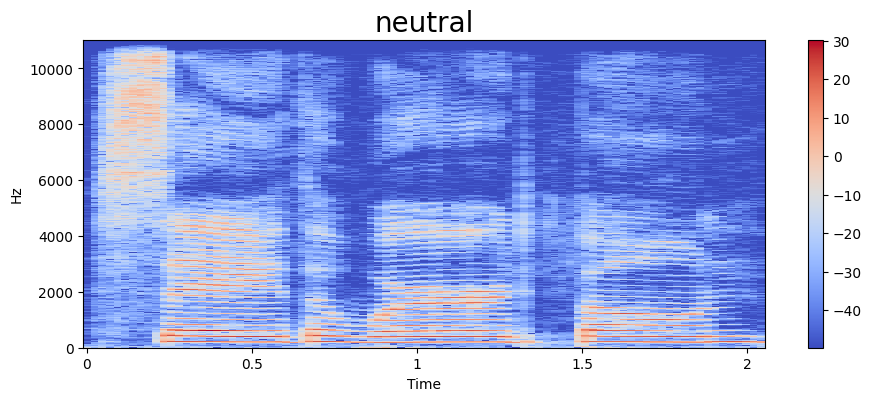

In [ ]:
emotion = 'neutral'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

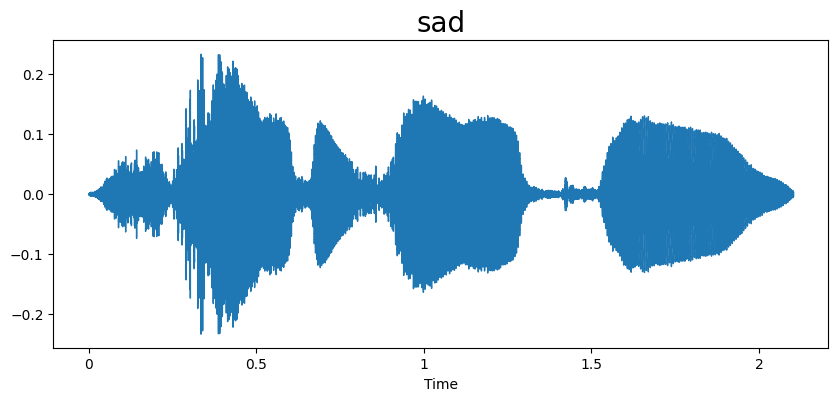

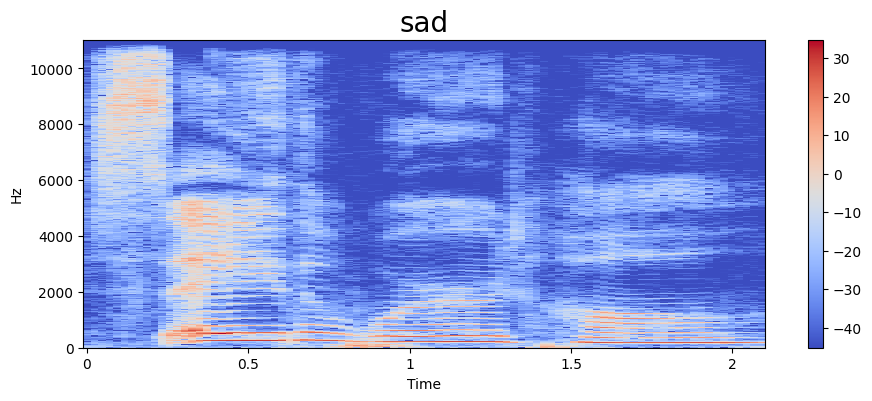

In [ ]:
emotion = 'sad'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

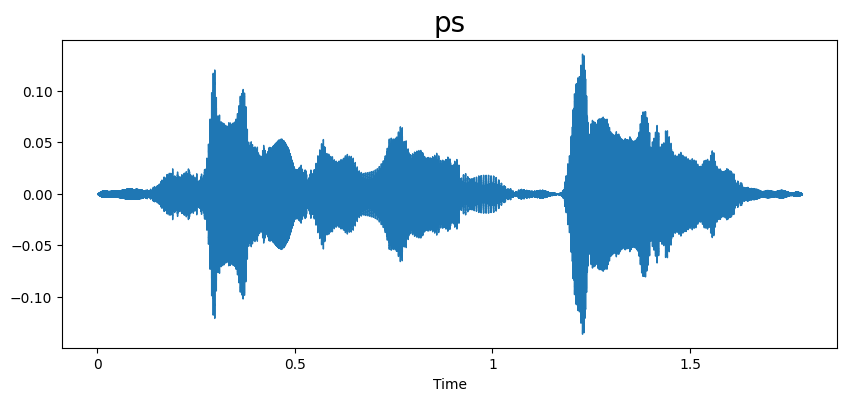

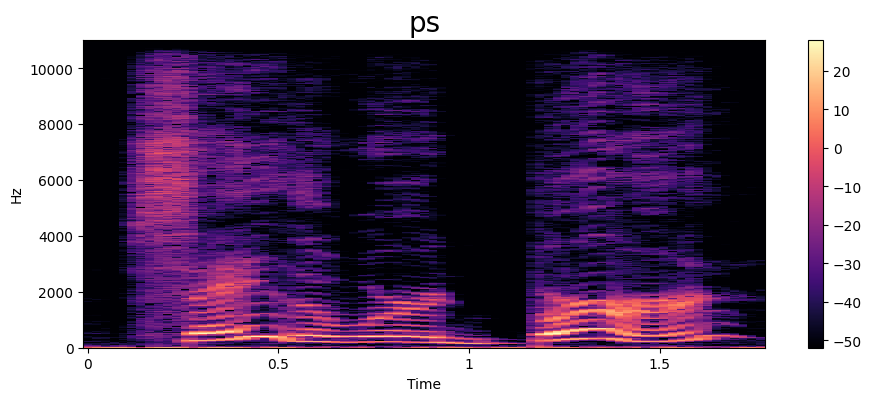

In [ ]:
emotion = 'ps'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

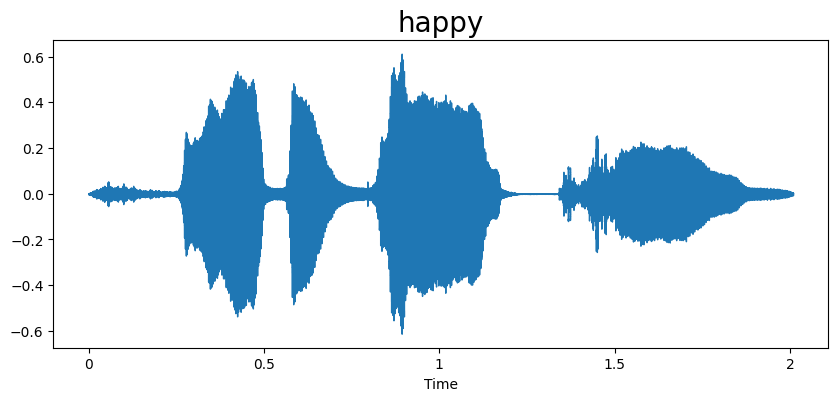

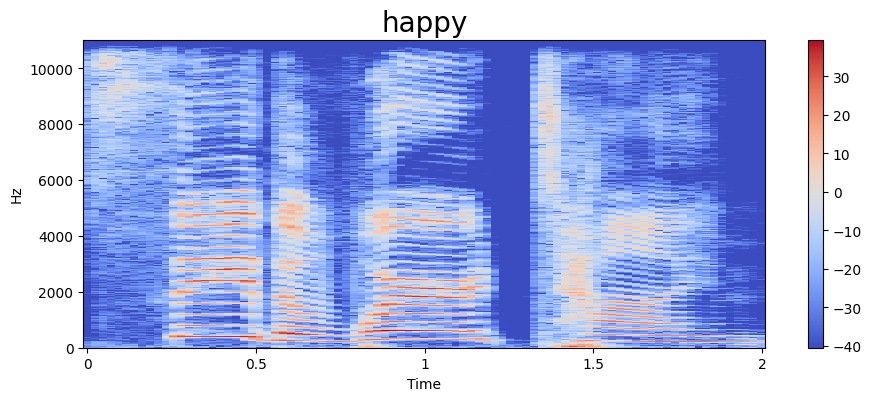

In [ ]:
emotion = 'happy'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

In [ ]:
# Feature Extraction
def extract_mfcc(filename):
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40).T, axis=0)
    return mfcc

In [ ]:
extract_mfcc(df['speech'][0])

array([-4.2960641e+02,  6.0449196e+01,  1.2524098e+01,  2.9926033e+01,
        3.5471644e+00,  2.4862245e-02, -1.0219502e+01, -1.0065463e+01,
       -1.4282920e+01, -4.3911276e+00, -6.9359651e+00, -6.8262541e-01,
       -7.9577975e+00,  4.5397015e+00, -2.6793051e+00, -3.2224588e+00,
        2.2950914e+00, -1.0505704e+00, -7.7180558e-01,  4.7563748e+00,
       -2.1692436e+00,  1.1005071e+00, -3.5484314e+00, -1.8314735e+00,
       -3.0673046e+00,  9.2670137e-01, -1.8915316e+00,  2.0212460e+00,
       -1.7748613e+00,  5.5224442e+00,  1.0996212e+00,  4.5028973e+00,
        1.2345446e+00,  3.7798185e+00,  7.8125815e+00,  5.5207720e+00,
        5.9797497e+00,  2.1649985e+00,  2.5308481e-01,  2.7430828e+00],
      dtype=float32)

In [ ]:
X_mfcc = df['speech'].apply(lambda x: extract_mfcc(x))

In [ ]:
X_mfcc

0       [-429.6064, 60.449196, 12.524098, 29.926033, 3...
1       [-405.26218, 75.615654, -9.759963, 14.846168, ...
2       [-440.4106, 122.641045, -8.854474, 20.866734, ...
3       [-409.6209, 105.88283, -21.932734, 8.138544, -...
4       [-439.7585, 71.21828, -13.219989, 22.715784, -...
                              ...                        
5595    [-525.6185, 72.173584, 30.458908, 2.2819052, 7...
5596    [-536.9873, 102.5276, 21.73846, -8.206102, 4.8...
5597    [-507.62088, 120.561485, 19.35497, -9.1734495,...
5598    [-503.94327, 89.68131, 16.924849, -4.0909452, ...
5599    [-484.50507, 74.074265, 24.3775, -9.382557, 7....
Name: speech, Length: 5600, dtype: object

In [ ]:
X = [x for x in X_mfcc]
X = np.array(X)
X.shape

(5600, 40)

In [ ]:
## input split
X = np.expand_dims(X, -1)
X.shape

(5600, 40, 1)

In [ ]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
y = enc.fit_transform(df[['label']])

In [ ]:
y = y.toarray()

In [ ]:
y.shape

(5600, 7)

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout

model = Sequential([
    LSTM(256, return_sequences=False, input_shape=(40,1)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(7, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 256)               264192    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense (Dense)               (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dropout_2 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 7)                 4

In [ ]:
# Train the model
history = model.fit(X, y, validation_split=0.2, epochs=50, batch_size=64)

Epoch 1/50
70/70 [==============================] - 25s 312ms/step - loss: 0.8065 - accuracy: 0.6951 - val_loss: 0.6267 - val_accuracy: 0.7937
Epoch 2/50
70/70 [==============================] - 21s 304ms/step - loss: 0.2376 - accuracy: 0.9266 - val_loss: 0.2373 - val_accuracy: 0.9232
Epoch 3/50
70/70 [==============================] - 14s 207ms/step - loss: 0.1471 - accuracy: 0.9563 - val_loss: 0.5441 - val_accuracy: 0.8339
Epoch 4/50
70/70 [==============================] - 14s 207ms/step - loss: 0.1200 - accuracy: 0.9641 - val_loss: 0.1970 - val_accuracy: 0.9321
Epoch 5/50
70/70 [==============================] - 14s 206ms/step - loss: 0.0963 - accuracy: 0.9708 - val_loss: 0.2136 - val_accuracy: 0.9179
Epoch 6/50
70/70 [==============================] - 15s 208ms/step - loss: 0.0943 - accuracy: 0.9710 - val_loss: 0.1625 - val_accuracy: 0.9473
Epoch 7/50
70/70 [==============================] - 15s 208ms/step - loss: 0.0693 - accuracy: 0.9786 - val_loss: 0.1950 - val_accuracy: 0.9420

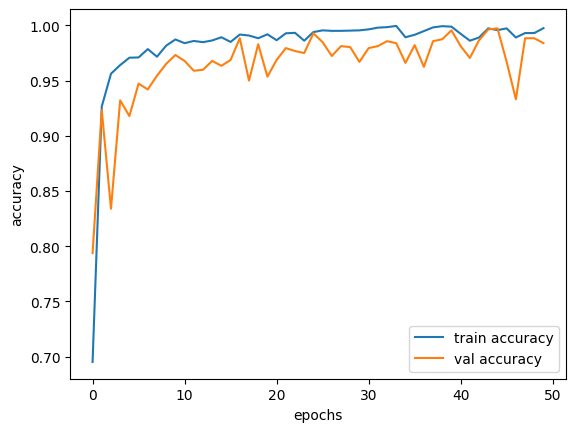

In [ ]:
epochs = list(range(50))
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.plot(epochs, acc, label='train accuracy')
plt.plot(epochs, val_acc, label='val accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()


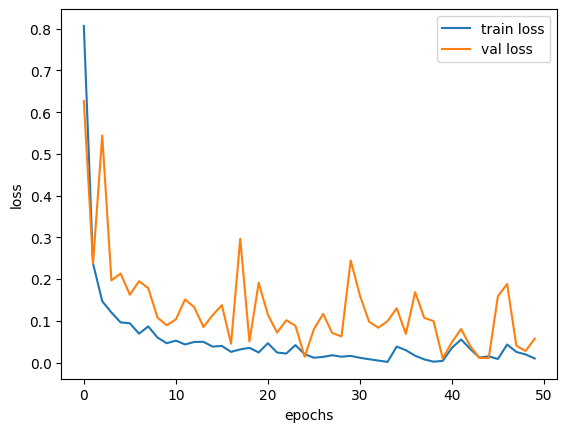

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs, loss, label='train loss')
plt.plot(epochs, val_loss, label='val loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.show()
